# Cosmic muon tracks reveal a spatial scattering field

## 1. Problem

This notebook actively reconstructs the **full author GEANT4/CRY statue acquisition**,522963 muons with six recorded XYZ detector positions each. This is author-supplied simulated observation data, not a measured museum experiment. The result is an angular-scattering RMS field on a36×80×40 spatial grid. It is a material-contrast proxy conditional on a single effective interaction, not calibrated mass density.

A numerical source audit identified three geometric discrepancies: a partial direction-vector sign flip, absolute values inside a dot-product sum, and an excessively restrictive componentwise nonparallel test. The default local method restores the paper's line, angle and nonparallel geometry. We independently ran both the unchanged source and its three-line qualified correction before extraction. This notebook labels and actively compares them; it does not claim unchanged-source numerical parity for the corrected method.

In [1]:
import os,sys,time,json
from pathlib import Path
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
root=Path.cwd()
if not (root/'src').exists():root=root.parent
sys.path.insert(0,str(root));torch.set_num_threads(1)
from src.preprocessing import load_data
from src.physics_model import fit_tracks,scattering_angles,nonparallel_mask,closest_approach,aggregate_rms
from src.solvers import reconstruct
from src.visualization import metrics,slice_panel
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'figure.dpi':110,'savefig.dpi':180,'axes.spines.top':False,'axes.spines.right':False})
hits=load_data(root/'data/raw_data.npz')
qualified=np.load(root/'evaluation/baseline_reference.npz',allow_pickle=False)['reconstruction'][0]
old=np.load(root/'notebooks/reference_outputs/unchanged_original.npz',allow_pickle=False)
print('Actual kernel:',sys.executable,'NumPy',np.__version__,'PyTorch',torch.__version__)
print('Full bound events:',len(hits),'input XYZ units mm; no energies, target material labels or reconstructed vertices are supplied.')

Actual kernel: D:\yan1\agent\AutoSkill\imaging-101-maintainer\research-runtime\Scripts\python.exe NumPy 2.4.6 PyTorch 2.9.1+cu128
Full bound events: 522963 input XYZ units mm; no energies, target material labels or reconstructed vertices are supplied.


## 2. Data

The source records only muons traversing all six detector planes. Every recorded event is kept; the reconstruction's subsequent geometric filtering is explicit. The upper three hits and lower three hits determine the incoming and outgoing trajectories. A few recorded z coordinates vary within the detector depth. These are preserved exactly rather than replaced by nominal planar coordinates.

The original acquisition's stored coordinates already have finite decimal precision. We add neither position smearing nor efficiency losses. The source's optional noisy-detector example is a different observation configuration. The selected ideal stored-hit configuration agrees with the ideal-detector assumption in the paper, while the native recorded z variation remains an identified data detail.

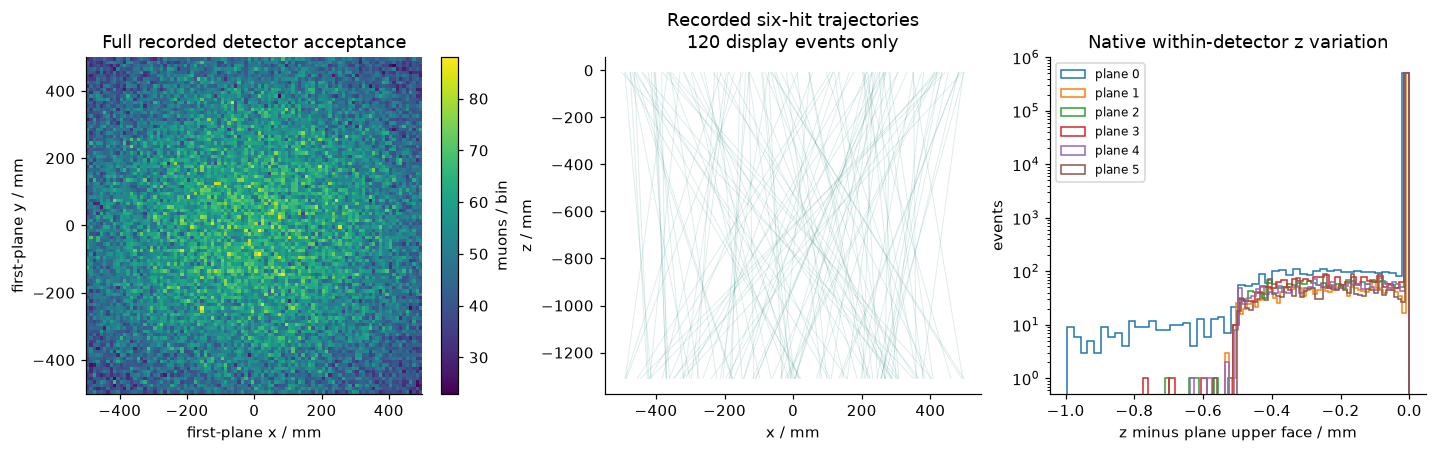

Per-plane minimum z / mm: [  -10.4963  -410.036   -460.212   -860.276   -910.139  -1310.07  ]
Per-plane maximum z / mm: [   -9.5  -409.5  -459.5  -859.5  -909.5 -1309.5]


In [2]:
fig_data,axs=plt.subplots(1,3,figsize=(13,4),layout='constrained')
h,xe,ye=np.histogram2d(hits[:,0,0],hits[:,0,1],bins=100)
im=axs[0].imshow(h.T,origin='lower',extent=[xe[0],xe[-1],ye[0],ye[-1]],cmap='viridis');fig_data.colorbar(im,ax=axs[0],label='muons / bin');axs[0].set(xlabel='first-plane x / mm',ylabel='first-plane y / mm',title='Full recorded detector acceptance')
for row in hits[::max(1,len(hits)//120)]:axs[1].plot(row[:,0],row[:,2],color='#1b7f79',alpha=.15,lw=.6)
axs[1].set(xlabel='x / mm',ylabel='z / mm',title='Recorded six-hit trajectories\n120 display events only')
for i in range(6):axs[2].hist(hits[:,i,2]-hits[:,i,2].max(),bins=50,histtype='step',label=f'plane {i}')
axs[2].set(xlabel='z minus plane upper face / mm',ylabel='events',yscale='log',title='Native within-detector z variation');axs[2].legend(fontsize=8)
plt.show()
print('Per-plane minimum z / mm:',hits[:,:,2].min(0));print('Per-plane maximum z / mm:',hits[:,:,2].max(0))

## 3. Physics

For three detector hits $h_j$ in one tracker, a line $p+t u$ approximates the trajectory. Its centroid $p$ minimizes the offset residual, and its principal singular vector $u$ minimizes orthogonal squared distances. Orienting $u$ downwards must reverse the whole vector when necessary, preserving the same line. Angular deflection is the geometric angle

$$\theta=\arccos\frac{u\cdot v}{\|u\|\|v\|},$$

where $v$ is the outgoing direction. The cross-product norm tests whether the lines are nonparallel. The shortest connector is perpendicular to both lines; its midpoint is the effective interaction location. This single-dominant-scatter approximation is imperfect because real muons scatter throughout their paths. Unknown momenta and variable path length prevent interpreting angular RMS directly as mass density.

The spatial statistic is $q_v=\sqrt{\sum_{n\in v}\theta_n^2/c_v}$, where $c_v$ is voxel event count. Empty voxels have zero estimate. We preserve source upper-tail clipping:99.9th percentile of retained angles before accumulation and99.9th percentile of the full voxel field afterwards. Both thresholds are computed without material truth.

{
  "fresh_seconds": 2.7989331999997376,
  "fresh_vs_qualified_original": {
    "ncc": 0.9999999999999999,
    "nrmse": 0.0
  },
  "retained_events": 220601,
  "count_conservation": 220601
}


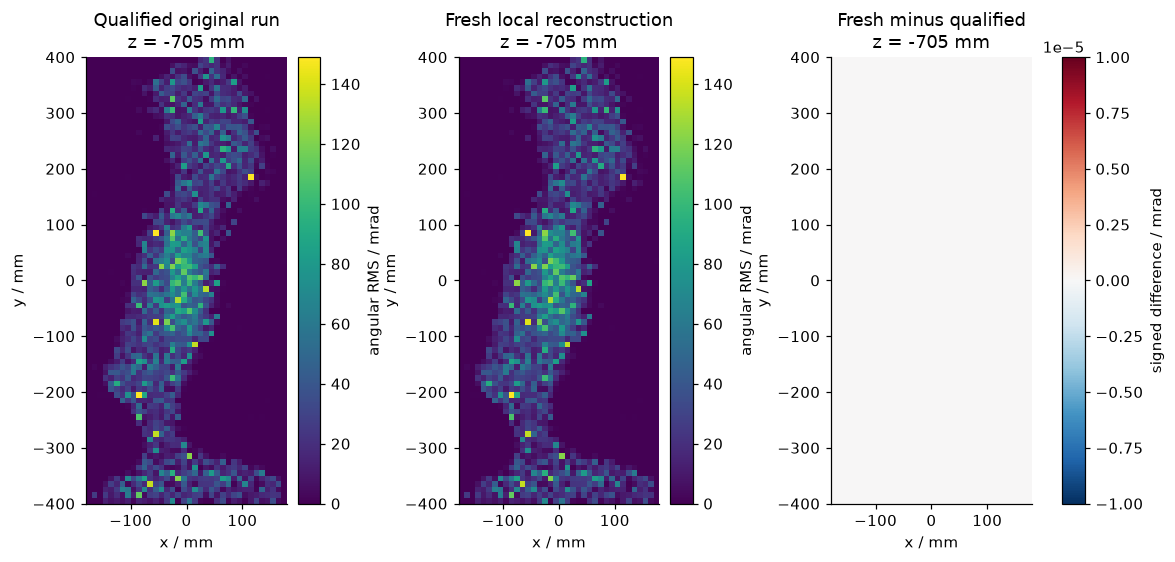

In [3]:
started=time.perf_counter();fresh,stage=reconstruct(hits,return_stages=True);fresh_seconds=time.perf_counter()-started
np.savez_compressed(root/'output/reconstruction.npz',reconstruction=fresh[None])
parity=metrics(fresh,qualified)
print(json.dumps({'fresh_seconds':fresh_seconds,'fresh_vs_qualified_original':parity,'retained_events':len(stage['pocas']),'count_conservation':int(stage['counts'].sum())},indent=2))
assert int(stage['counts'].sum())==len(stage['pocas'])
zslice=15;lim=float(max(fresh.max(),qualified.max()))*1000
fig_parity,axs=plt.subplots(1,3,figsize=(10.5,5),layout='constrained')
for ax,a,title in zip(axs[:2],[qualified,fresh],['Qualified original run','Fresh local reconstruction']):im=slice_panel(ax,a,zslice,title,vmax=lim);fig_parity.colorbar(im,ax=ax,label='angular RMS / mrad')
difference=fresh-qualified;errlim=max(float(np.max(abs(difference)))*1000,1e-5)
im=slice_panel(axs[2],difference,zslice,'Fresh minus qualified',vmax=errlim,signed=True);fig_parity.colorbar(im,ax=axs[2],label='signed difference / mrad')
plt.show()

## 4. Method and numerical-source audit

The cleaned implementation evaluates the same qualified SVD fits, batched3×3 line solves, inclusive finite-volume selection and clipped per-voxel statistics locally. It replaces the original exhaustive event-by-all-voxel interval masks with mathematically equivalent sorted-edge lookup. Internal shared-edge ties select the upper voxel; the global maximum remains in the last cell. Frozen full-array indices/counts and boundary cases verify this convention.

The next cell actively reconstructs the unchanged source mathematics and then adds each minimal correction in sequence. All four results use the same bound detector observations and fixed box. The unchanged field is compared against its independently executed original numeric result. Intermediate rows are actual computed ablations, not zeros or reused reference arrays. These comparisons measure the effect of source errors, rather than uncertainty in the physical specimen.

Fresh historical branch vs independently run unchanged original: {'ncc': 1.0, 'nrmse': 0.0}
[
  {
    "method": "Unchanged source",
    "seconds": 2.8851570000115316,
    "retained": 217513,
    "ncc": 0.9882097842218399,
    "nrmse": 0.017784747674236177
  },
  {
    "method": "Whole-vector orientation",
    "seconds": 2.8904853999993065,
    "retained": 217517,
    "ncc": 0.9882097681315782,
    "nrmse": 0.017784739780011456
  },
  {
    "method": "Geometric angle",
    "seconds": 2.9210567999980412,
    "retained": 217517,
    "ncc": 0.9999725920167648,
    "nrmse": 0.000811849522053233
  },
  {
    "method": "Geometric nonparallel norm",
    "seconds": 2.7989331999997376,
    "retained": 220601,
    "ncc": 0.9999999999999999,
    "nrmse": 0.0
  }
]


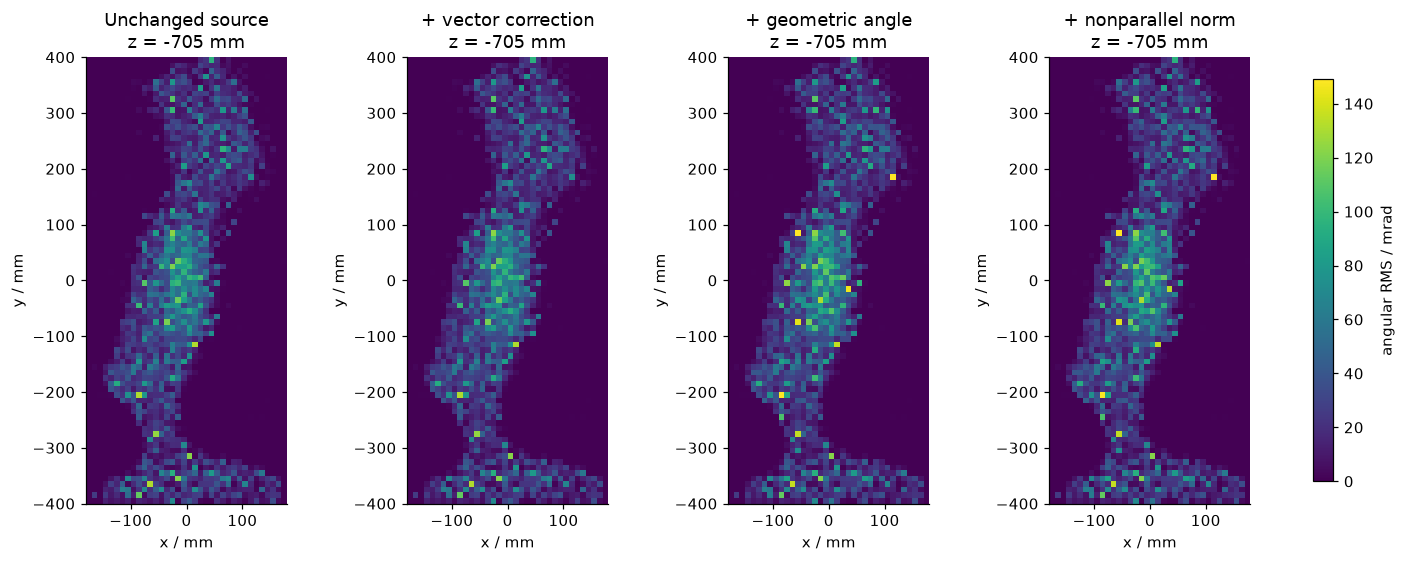

Historical angular error >1 mrad: 3654 maximum / rad: 0.76169753
Additional valid tracks excluded by componentwise cut: 24965


In [4]:
states=[];state_stats=[]
for name,flags in [('Unchanged source',(False,False,False)),('Whole-vector orientation',(True,False,False)),('Geometric angle',(True,True,False))]:
 started=time.perf_counter();a,s=reconstruct(hits,return_stages=True,correct_direction=flags[0],correct_angle=flags[1],correct_mask=flags[2]);seconds=time.perf_counter()-started
 states.append(a);state_stats.append({'method':name,'seconds':seconds,'retained':len(s['pocas']),**metrics(a,qualified)})
 if not any(flags):historical_stage=s
states.append(fresh);state_stats.append({'method':'Geometric nonparallel norm','seconds':fresh_seconds,'retained':len(stage['pocas']),**metrics(fresh,qualified)})
print('Fresh historical branch vs independently run unchanged original:',metrics(states[0],old['scattering_rms']))
print(json.dumps(state_stats,indent=2))
fig_audit,axs=plt.subplots(1,4,figsize=(13,5),layout='constrained')
common=float(max(a.max() for a in states))*1000
for ax,a,title in zip(axs,states,['Unchanged source','+ vector correction','+ geometric angle','+ nonparallel norm']):
 im=slice_panel(ax,a,zslice,title,vmax=common)
fig_audit.colorbar(im,ax=axs,label='angular RMS / mrad',shrink=.9)
plt.show()
angle_error=historical_stage['angles']-stage['angles'];extra_rejected=int(np.count_nonzero(stage['parallel_mask']&~historical_stage['parallel_mask']))
print('Historical angular error >1 mrad:',np.count_nonzero(abs(angle_error)>.001),'maximum / rad:',np.max(abs(angle_error)))
print('Additional valid tracks excluded by componentwise cut:',extra_rejected)

## 5. Results and scientific comparisons

Orthogonal sections expose the three-dimensional structure rather than relying on a single viewing plane. Count occupancy and angular RMS answer different questions: a voxel may contain many low-angle events or a few large-angle events. Neither is a known density truth. The following panels use native voxel geometry and every retained event. Color scales for angular fields are shared, with rad converted to mrad only for display.

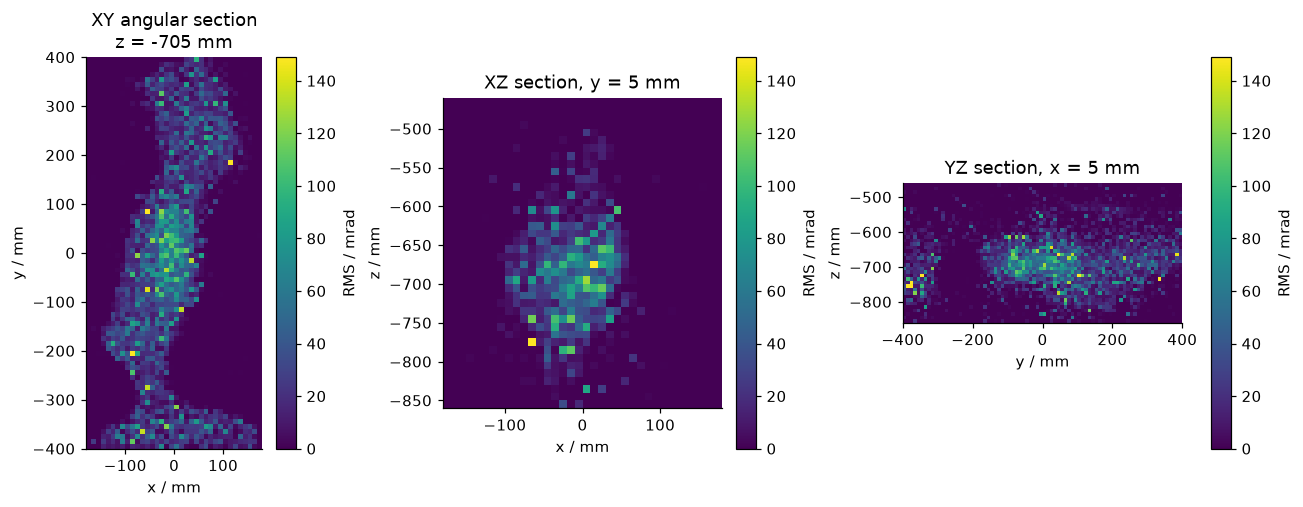

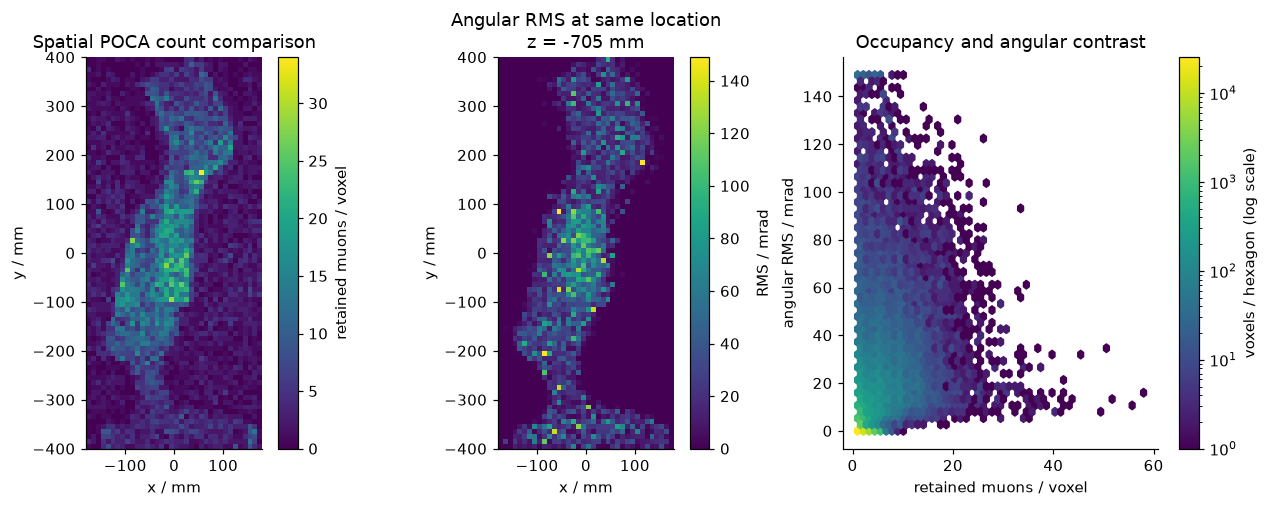

Populated voxels: 74092 / 115200 largest occupancy: 58


In [5]:
fig_sections,axs=plt.subplots(1,3,figsize=(12,4.5),layout='constrained')
im=slice_panel(axs[0],fresh,zslice,'XY angular section',vmax=lim);fig_sections.colorbar(im,ax=axs[0],label='RMS / mrad')
im=axs[1].imshow(fresh[:,40,:].T*1000,origin='lower',extent=[-180,180,-860,-460],vmin=0,vmax=lim,cmap='viridis',aspect='equal');axs[1].set(xlabel='x / mm',ylabel='z / mm',title='XZ section, y = 5 mm');fig_sections.colorbar(im,ax=axs[1],label='RMS / mrad')
im=axs[2].imshow(fresh[18,:,:].T*1000,origin='lower',extent=[-400,400,-860,-460],vmin=0,vmax=lim,cmap='viridis',aspect='equal');axs[2].set(xlabel='y / mm',ylabel='z / mm',title='YZ section, x = 5 mm');fig_sections.colorbar(im,ax=axs[2],label='RMS / mrad');plt.show()
fig_occupancy,axs=plt.subplots(1,3,figsize=(12,4.5),layout='constrained')
im=axs[0].imshow(stage['counts'][:,:,zslice].T,origin='lower',extent=[-180,180,-400,400],cmap='viridis',aspect='equal');fig_occupancy.colorbar(im,ax=axs[0],label='retained muons / voxel');axs[0].set(xlabel='x / mm',ylabel='y / mm',title='Spatial POCA count comparison')
im=slice_panel(axs[1],fresh,zslice,'Angular RMS at same location',vmax=lim);fig_occupancy.colorbar(im,ax=axs[1],label='RMS / mrad')
counts=stage['counts'].ravel();mask=counts>0
im=axs[2].hexbin(counts[mask],fresh.ravel()[mask]*1000,gridsize=50,mincnt=1,bins='log',cmap='viridis');fig_occupancy.colorbar(im,ax=axs[2],label='voxels / hexagon (log scale)');axs[2].set(xlabel='retained muons / voxel',ylabel='angular RMS / mrad',title='Occupancy and angular contrast');plt.show()
print('Populated voxels:',mask.sum(),'/',len(mask),'largest occupancy:',counts.max())

### Upper-tail sensitivity on the same full acquisition

The source suppresses very large scattering angles, which can reflect low-momentum particles as well as strong material interactions. We compute angular clipping quantiles0.99,0.999 and1.0 using exactly the same retained geometric events. Each per-voxel aggregation is fresh; the final voxel clipping remains0.999. The standard submission stays at the source's0.999 setting. No selection is optimized against a specimen truth.

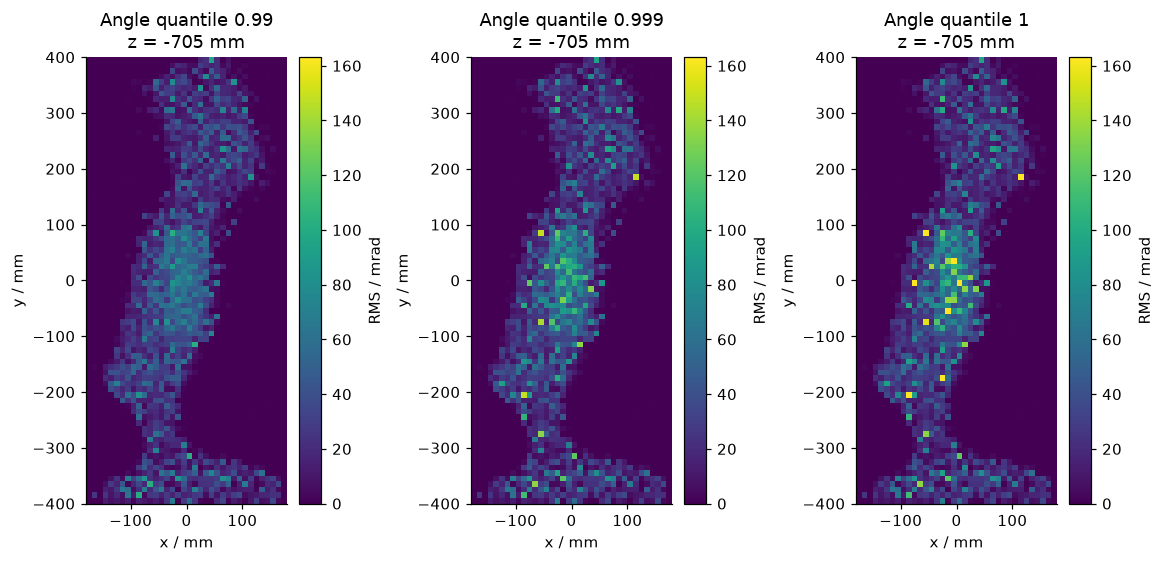

Sensitivity vs standard: [
  {
    "ncc": 0.9771494387689375,
    "nrmse": 0.02626549800538647
  },
  {
    "ncc": 0.9999999999999999,
    "nrmse": 0.0
  },
  {
    "ncc": 0.9977852900154606,
    "nrmse": 0.007770656420873896
  }
]


In [6]:
quantiles=np.array([.99,.999,1.]);sensitivity=[];sensitivity_metrics=[]
for quantile in quantiles:
 a,c=aggregate_rms(stage['indices'],stage['retained_angles'],angle_quantile=float(quantile),prediction_quantile=.999);sensitivity.append(a);sensitivity_metrics.append(metrics(a,fresh))
fig_sensitivity,axs=plt.subplots(1,3,figsize=(10.5,5),layout='constrained');clim=max(a.max() for a in sensitivity)*1000
for ax,a,quantile in zip(axs,sensitivity,quantiles):
 im=slice_panel(ax,a,zslice,f'Angle quantile {quantile:g}',vmax=clim);fig_sensitivity.colorbar(im,ax=ax,label='RMS / mrad')
plt.show();print('Sensitivity vs standard:',json.dumps(sensitivity_metrics,indent=2))

### Independent geometry and finite-precision checks

For nonparallel lines, independently minimize the squared connector length using a2×2 Gram system. With $a=u\cdot u$, $b=u\cdot v$, $c=v\cdot v$, $d=u\cdot(q-p)$ and $e=v\cdot(q-p)$, the closest-line parameters are

$$t=(cd-be)/(ac-b^2),\qquad s=(bd-ae)/(ac-b^2).$$

This is independent of the source's3×3 common-perpendicular solve. We evaluate it in float64 on a fixed nondegenerate subset of the retained full-data tracks. The angle is also checked with the independent identity $\theta=\operatorname{atan2}(\|u\times v\|,u\cdot v)$. Float32 acos loses angular resolution close to zero, so that precision limitation is measured and disclosed rather than attributed to density contrast.

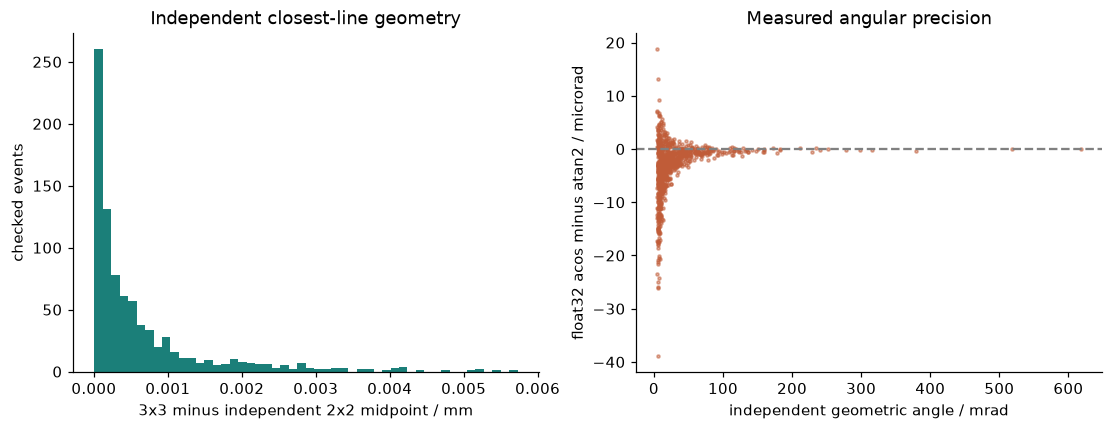

{
  "independent_lines_checked": 858,
  "midpoint_max_mm": 0.005728335569937775,
  "connector_dot_u_max_mm": 6.385285689081144e-09,
  "connector_dot_v_max_mm": 6.385300430761243e-09,
  "acos_vs_atan_max_rad": 3.893007511343409e-05
}


In [7]:
selected=np.flatnonzero(stage['parallel_mask']);selected=selected[stage['volume_mask']]
valid=selected[stage['angles'][selected]>.005][::100]
u=stage['tracks_in'][valid].astype(float);v=stage['tracks_out'][valid].astype(float);p=stage['points_in'][valid].astype(float);q=stage['points_out'][valid].astype(float)
a=np.sum(u*u,axis=1);b=np.sum(u*v,axis=1);c=np.sum(v*v,axis=1);d=np.sum(u*(q-p),axis=1);e=np.sum(v*(q-p),axis=1);den=a*c-b*b
t=(c*d-b*e)/den;s=(b*d-a*e)/den;left=p+t[:,None]*u;right=q+s[:,None]*v
independent_midpoint=(left+right)/2;source_midpoint=closest_approach(p.astype(np.float32),q.astype(np.float32),u.astype(np.float32),v.astype(np.float32)).astype(float)
connector=right-left;midpoint_error=np.linalg.norm(independent_midpoint-source_midpoint,axis=1)
angle_atan=np.arctan2(np.linalg.norm(np.cross(u,v),axis=1),np.sum(u*v,axis=1));angle_difference=stage['angles'][valid]-angle_atan
physics={'independent_lines_checked':len(valid),'midpoint_max_mm':float(midpoint_error.max()),'connector_dot_u_max_mm':float(abs(np.sum(connector*u,axis=1)).max()),'connector_dot_v_max_mm':float(abs(np.sum(connector*v,axis=1)).max()),'acos_vs_atan_max_rad':float(abs(angle_difference).max())}
fig_physics,axs=plt.subplots(1,2,figsize=(10,3.8),layout='constrained');axs[0].hist(midpoint_error,bins=50,color='#1b7f79');axs[0].set(xlabel='3x3 minus independent 2x2 midpoint / mm',ylabel='checked events',title='Independent closest-line geometry');axs[1].scatter(angle_atan*1000,angle_difference*1e6,s=4,alpha=.5,color='#c05c38');axs[1].axhline(0,color='gray',ls='--');axs[1].set(xlabel='independent geometric angle / mrad',ylabel='float32 acos minus atan2 / microrad',title='Measured angular precision');plt.show();print(json.dumps(physics,indent=2))
assert physics['midpoint_max_mm']<.05
assert physics['connector_dot_u_max_mm']<1e-5 and physics['connector_dot_v_max_mm']<1e-5

## 6. Conclusion

The fresh local qualified reconstruction processes the entire bound acquisition and agrees with the independently run corrected author implementation. An additional actively computed historical branch reproduces the unchanged original implementation, while the three source-error ablations quantify each minimal correction's spatial effect. Independent line geometry, physical units, boundary assignment and count conservation supplement numeric parity.

The image remains conditional on a single effective scatter, unknown particle momentum, finite detector precision, upper-tail clipping and sparse voxel occupancy. It is angular material contrast rather than an independently validated density field. The paper's broader clustering, absorption-tomography and noisy-detector studies are not claimed as this selected benchmark experiment. All fresh fields, sensitivities and plotted metrics were actually computed; identified original arrays are comparisons only.

In [8]:
import importlib.util
spec=importlib.util.spec_from_file_location('standalone_muon_judge',root/'evaluation/judge.py');judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report,status=judge.evaluate(root/'output/reconstruction.npz');assert status==0;print(json.dumps(report,indent=2))
private=os.environ.get('IMAGING101_MUON_EXPORT')
if private:
 export=Path(private);export.mkdir(parents=True,exist_ok=True)
 for i,fig in enumerate([fig_data,fig_parity,fig_audit,fig_sections,fig_occupancy,fig_sensitivity,fig_physics],1):
  for ext in ['png','svg','pdf']:fig.savefig(export/f'muon-{i}.{ext}',bbox_inches='tight')
 np.savez_compressed(export.parent/'muon_experiments.npz',fresh=fresh,source_states=np.stack(states),counts=stage['counts'],quantiles=quantiles,sensitivity_fields=np.stack(sensitivity),independent_midpoint_error_mm=midpoint_error,independent_angle_difference_rad=angle_difference)
 summary={'fresh_seconds':fresh_seconds,'qualified_parity':parity,'unchanged_parity':metrics(states[0],old['scattering_rms']),'state_statistics':state_stats,'sensitivity':sensitivity_metrics,'physics':physics,'judge':report,'actual_kernel':sys.executable,'numpy':np.__version__,'torch':torch.__version__}
 (export.parent/'muon_experiments.json').write_text(json.dumps(summary,indent=2),encoding='utf8')
plt.close('all')

{
  "status": "pass",
  "passed": true,
  "metrics": {
    "ncc": 0.9999999999999999,
    "nrmse": 0.0
  },
  "thresholds": {
    "ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "nrmse": {
      "comparison": "<=",
      "boundary": 5e-06
    }
  },
  "errors": []
}
